# Fase 8b — Construcción de la región de prueba de Lima

**Decisiones (de la fase 8a):**
- **Escena SAR:** Sentinel-1B, **17/03/2017 10:38 UTC**, pasada **descendente**, órbita relativa 171, **VV+VH**. (Las ascendentes sobre Lima son solo VV → inservibles para nuestra U-Net.) El propio equipo de Copernicus EMS usó S1 del 17 y 18/03 (capa `grid200`).
- **Etiqueta:** `Potential_Maximum_flood` del EMSN038 = extensión máxima de inundación delineada (OBIA) sobre WorldView-2 del 18 y 21/03/2017.
- **Codificación:** 1 = inundado · 0 = observado por WorldView-2 dentro del AOI y no inundado · −1 = no observado, o cauce (`WatrcrsA`) fuera de la inundación (no sabemos si tenía agua) · −1 también donde el SAR no tiene dato.
- **Formato idéntico a Sen1Floods11:** EPSG:4326, 8.983e-05° (~10 m), chips 512×512, VV/VH en dB (σ⁰ de `COPERNICUS/S1_GRD`, el mismo catálogo con el que se generó Sen1Floods11).

**Descarga:** chip por chip con `ee.data.computePixels` (sin exportar a Drive). Los chips se guardan en `datos_lima/chips/`. **Reanudable:** si se corta, los chips ya bajados no se vuelven a pedir. No necesita GPU.

## 0. Preparación

In [1]:
from google.colab import drive
drive.mount('/content/drive')

import sys
from pathlib import Path
RAIZ_PROYECTO = Path('/content/drive/MyDrive/rnap_p2_inundaciones')
sys.path.insert(0, str(RAIZ_PROYECTO))

!pip install -q geopandas pyogrio earthengine-api rasterio

Mounted at /content/drive


## 1. Módulo nuevo: `src/lima_chips.py`

In [2]:
%%writefile /content/drive/MyDrive/rnap_p2_inundaciones/src/lima_chips.py
"""
lima_chips.py
Fase 8b: construir la región de prueba de Lima con el MISMO formato que Sen1Floods11.
  - Grilla EPSG:4326 con la resolución de Sen1Floods11 (8.983e-05° ≈ 10 m), chips de 512 x 512.
  - S1 (VV, VH en dB) descargado chip por chip desde Earth Engine con ee.data.computePixels
    (sin exportar a Drive; cada chip ~2 MB, muy por debajo del límite de 48 MB por pedido).
  - Etiqueta rasterizada desde EMSN038:
        -1 : fuera del área observada por WorldView-2 o cauce dudoso
         0 : observado y no inundado
         1 : extensión máxima de inundación (Potential_Maximum_flood)
  Se guardan como Lima_<fila>_<col>_S1Hand.tif / _LabelHand.tif para reutilizar ConjuntoInundaciones.
"""
import numpy as np
import pandas as pd
import rasterio
from rasterio.features import rasterize
from rasterio.transform import Affine
import shapely
from shapely.ops import unary_union

RESOLUCION_SEN1FLOODS11 = 8.983152841195215e-05   # grados (verificado en la fase 0)
TAMANO = 512
SIN_DATO_EE = -9999.0


# ----------------------------------------------------------------------------- geometrías EMS
def preparar_geometrias(dir_ems, gdb="EMSN038_UTM18S_v0.gdb", cauce="ignorar"):
    """Devuelve las geometrías (en EPSG:4326) que definen la etiqueta.
    cauce: qué hacer con WatrcrsA fuera de la inundación -> 'ignorar' (-1), 'no_agua' (0) o 'agua' (1)."""
    import geopandas as gpd
    leer = lambda capa: gpd.read_file(dir_ems / gdb, layer=capa)
    aoi = leer("EMSN038_AOI")
    huellas = leer("Footprints")
    huellas_wv2 = huellas[huellas["SDP"].astype(str).str.contains("WorldView", case=False)]
    observado = shapely.force_2d(unary_union(huellas_wv2.geometry)).intersection(
        shapely.force_2d(unary_union(aoi.geometry)))       # el AOI viene en 3D (Z/M)
    inundacion = unary_union(leer("Potential_Maximum_flood").geometry)
    cauces = unary_union(leer("WatrcrsA").geometry)
    serie = gpd.GeoSeries([observado, inundacion, cauces], crs=aoi.crs).to_crs(4326)
    return {"observado": serie.iloc[0], "inundacion": serie.iloc[1], "cauces": serie.iloc[2],
            "cauce": cauce, "fechas_wv2": sorted(huellas_wv2["SDV"].astype(str).unique())}


def rasterizar_etiqueta(geometrias, transformacion, tamano=TAMANO):
    forma = (tamano, tamano)
    etiqueta = np.full(forma, -1, dtype=np.int16)
    quemar = lambda geom, valor: rasterize([(geom, valor)], out_shape=forma, transform=transformacion,
                                           fill=0, dtype="int16", all_touched=False).astype(bool)
    observado = quemar(geometrias["observado"], 1)
    etiqueta[observado] = 0
    if not geometrias["cauces"].is_empty:
        valor_cauce = {"ignorar": -1, "no_agua": 0, "agua": 1}[geometrias["cauce"]]
        etiqueta[quemar(geometrias["cauces"], 1) & observado] = valor_cauce
    etiqueta[quemar(geometrias["inundacion"], 1) & observado] = 1
    return etiqueta


# ----------------------------------------------------------------------------- grilla y S1
def definir_grilla(limites, resolucion=RESOLUCION_SEN1FLOODS11, tamano=TAMANO):
    """limites = (lon_min, lat_min, lon_max, lat_max) -> lista de (fila, col, Affine) cubriendo el área."""
    lon_min, lat_min, lon_max, lat_max = limites
    paso = resolucion * tamano
    n_col = int(np.ceil((lon_max - lon_min) / paso))
    n_fil = int(np.ceil((lat_max - lat_min) / paso))
    return [(f, c, Affine(resolucion, 0, lon_min + c * paso, 0, -resolucion, lat_max - f * paso))
            for f in range(n_fil) for c in range(n_col)]


def descargar_chip_s1(ee, imagen, transformacion, tamano=TAMANO):
    """VV y VH de un chip como (2, H, W) float32 en dB; NaN donde no hay dato."""
    pedido = {
        "expression": imagen.select(["VV", "VH"]).unmask(SIN_DATO_EE),
        "fileFormat": "NUMPY_NDARRAY",
        "grid": {"dimensions": {"width": tamano, "height": tamano},
                 "affineTransform": {"scaleX": transformacion.a, "shearX": 0, "translateX": transformacion.c,
                                     "shearY": 0, "scaleY": transformacion.e, "translateY": transformacion.f},
                 "crsCode": "EPSG:4326"},
    }
    datos = ee.data.computePixels(pedido)
    s1 = np.stack([datos["VV"], datos["VH"]]).astype(np.float32)
    s1[s1 <= SIN_DATO_EE + 1] = np.nan
    return s1


def escribir_tif(ruta, arreglo, transformacion, dtype):
    arreglo = arreglo if arreglo.ndim == 3 else arreglo[None]
    with rasterio.open(ruta, "w", driver="GTiff", height=arreglo.shape[1], width=arreglo.shape[2],
                       count=arreglo.shape[0], dtype=dtype, crs="EPSG:4326", transform=transformacion,
                       compress="deflate") as destino:
        destino.write(arreglo.astype(dtype))


def construir_chips(ee, imagen, geometrias, dir_s1, dir_etiqueta, minimo_observado=0.10):
    """Recorre la grilla sobre el área observada; guarda solo chips con >= minimo_observado de píxeles válidos."""
    from tqdm.auto import tqdm
    dir_s1.mkdir(parents=True, exist_ok=True); dir_etiqueta.mkdir(parents=True, exist_ok=True)
    filas = []
    for fila, col, transformacion in tqdm(definir_grilla(geometrias["observado"].bounds), desc="Chips Lima"):
        id_chip = f"Lima_{fila:02d}{col:02d}"
        etiqueta = rasterizar_etiqueta(geometrias, transformacion)
        fraccion_observada = (etiqueta != -1).mean()
        if fraccion_observada < minimo_observado:
            continue
        ruta_s1 = dir_s1 / f"{id_chip}_S1Hand.tif"
        if ruta_s1.exists():
            with rasterio.open(ruta_s1) as fuente:
                s1 = fuente.read()
        else:
            s1 = descargar_chip_s1(ee, imagen, transformacion)
            escribir_tif(ruta_s1, s1, transformacion, "float32")
        etiqueta[~np.isfinite(s1).all(axis=0)] = -1
        escribir_tif(dir_etiqueta / f"{id_chip}_LabelHand.tif", etiqueta, transformacion, "int16")
        validos = etiqueta != -1
        filas.append({"id_chip": id_chip, "fila": fila, "col": col,
                      "fraccion_valida": validos.mean(),
                      "px_agua": int((etiqueta == 1).sum()), "px_no_agua": int((etiqueta == 0).sum()),
                      "pct_agua_validos": 100 * (etiqueta == 1).sum() / max(validos.sum(), 1)})
    return pd.DataFrame(filas)


Writing /content/drive/MyDrive/rnap_p2_inundaciones/src/lima_chips.py


## 2. Earth Engine (cuenta de la UNI)

In [3]:
import ee
ee.Authenticate()
ee.Initialize(project='rnap-inundaciones')

## 3. Escena y geometrías de la etiqueta

In [4]:
import numpy as np
import pandas as pd
import geopandas as gpd
from src.configuracion import *
from src.lima_chips import preparar_geometrias, construir_chips

DIR_LIMA = RAIZ_PROYECTO / 'datos_lima'
escenas = pd.read_csv(DIR_RESULTADOS / 'f8_escenas_s1_lima.csv')
escena = escenas[escenas['fecha_hora'].str.startswith('2017-03-17') & escenas['polarizaciones'].str.contains('VH')].iloc[0]
print(escena[['id', 'fecha_hora', 'pasada', 'orbita_relativa', 'polarizaciones']])
imagen = ee.Image(f"COPERNICUS/S1_GRD/{escena['id']}")

dir_ems = next((DIR_LIMA / 'emsn038').rglob('EMSN038_UTM18S_v0.gdb')).parent     # carpeta que contiene el .gdb
geometrias = preparar_geometrias(dir_ems, cauce='ignorar')
areas = gpd.GeoSeries([geometrias['observado'], geometrias['inundacion'], geometrias['cauces']], crs=4326).to_crs(32718).area / 1e6
print('Fechas WorldView-2 de las huellas:', geometrias['fechas_wv2'])
print(f"Área observada (AOI ∩ WorldView-2): {areas[0]:.1f} km² | inundación: {areas[1]:.2f} km² | cauces: {areas[2]:.2f} km²")

id                 S1B_IW_GRDH_1SDV_20170317T103823_20170317T1038...
fecha_hora                                          2017-03-17 10:38
pasada                                                    DESCENDING
orbita_relativa                                                  171
polarizaciones                                                 VV+VH
Name: 5, dtype: object


/usr/local/lib/python3.13/dist-packages/pyogrio/raw.py:200: UserWarning: Measured (M) geometry types are not supported. Original type 'Measured 3D MultiPolygon' is converted to 'MultiPolygon Z'
  return ogr_read(


Fechas WorldView-2 de las huellas: ['2017-03-18 00:00:00+00:00', '2017-03-21 00:00:00+00:00']
Área observada (AOI ∩ WorldView-2): 1325.9 km² | inundación: 13.58 km² | cauces: 5.69 km²


## 4. Construir los chips (~unos minutos)
Solo se guardan chips con ≥ 10 % de píxeles observados.

In [5]:
df_chips = construir_chips(ee, imagen, geometrias, DIR_LIMA / 'chips' / 'S1Hand', DIR_LIMA / 'chips' / 'LabelHand',
                           minimo_observado=0.10)
df_chips.to_csv(DIR_RESULTADOS / 'f8_chips_lima.csv', index=False)
total_agua, total_no_agua = df_chips['px_agua'].sum(), df_chips['px_no_agua'].sum()
print(f"Chips: {len(df_chips)} | con agua: {(df_chips['px_agua'] > 0).sum()}")
print(f"Píxeles válidos: {total_agua + total_no_agua:,} | agua: {total_agua:,} ({100 * total_agua / (total_agua + total_no_agua):.2f} %)")
df_chips.sort_values('px_agua', ascending=False).head(10).round(3)

Chips Lima:   0%|          | 0/64 [00:00<?, ?it/s]

Chips: 64 | con agua: 19
Píxeles válidos: 13,051,948 | agua: 137,530 (1.05 %)


,id_chip,fila,col,fraccion_valida,px_agua,px_no_agua,pct_agua_validos
46,Lima_0506,5,6,0.999,45495,216343,17.375
45,Lima_0505,5,5,0.999,28337,233496,10.823
47,Lima_0507,5,7,0.574,13138,137250,8.736
12,Lima_0104,1,4,0.999,11420,250577,4.359
19,Lima_0203,2,3,1.000,5832,256201,2.226
38,Lima_0406,4,6,1.000,5723,256421,2.183
4,Lima_0004,0,4,0.584,5495,147493,3.592
49,Lima_0601,6,1,0.982,3910,253497,1.519
52,Lima_0604,6,4,0.999,3274,258639,1.250
33,Lima_0401,4,1,0.670,2018,173670,1.149


## 5. Ejemplos: los 4 chips con más agua

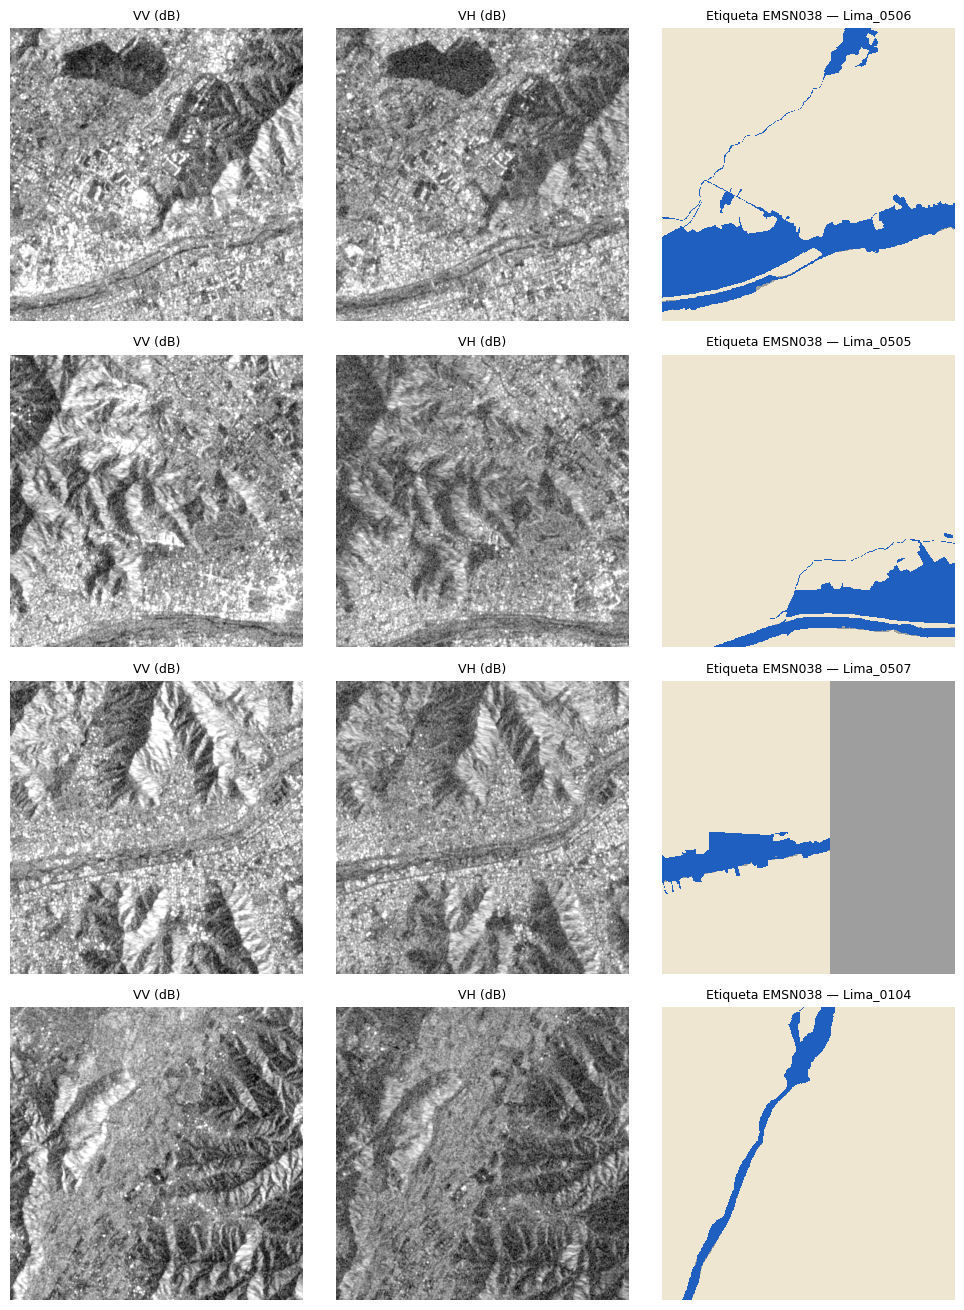

In [6]:
import matplotlib.pyplot as plt
import rasterio
from src.visualizacion import mostrar_sar, mostrar_mascara

def leer(ruta):
    with rasterio.open(ruta) as f:
        return f.read()

top = df_chips.sort_values('px_agua', ascending=False).head(4)['id_chip']
figura, ejes = plt.subplots(len(top), 3, figsize=(10, 3.3 * len(top)))
for fila, id_chip in enumerate(top):
    s1 = leer(DIR_LIMA / 'chips' / 'S1Hand' / f'{id_chip}_S1Hand.tif')
    etiqueta = leer(DIR_LIMA / 'chips' / 'LabelHand' / f'{id_chip}_LabelHand.tif')[0]
    mostrar_sar(ejes[fila, 0], s1[0], 'VV'); mostrar_sar(ejes[fila, 1], s1[1], 'VH')
    mostrar_mascara(ejes[fila, 2], etiqueta, f'Etiqueta EMSN038 — {id_chip}')
figura.tight_layout(); figura.savefig(DIR_FIGURAS / 'f8_chips_lima_ejemplos.png', dpi=150, bbox_inches='tight')

## 6. ¿Se parece Lima a lo que vio la red? Distribución de VV/VH por clase
Comparamos los píxeles de **agua** y **no agua** de Lima con los de **train** de Sen1Floods11. Si el agua de Lima es mucho más **brillante** (doble rebote urbano, agua turbulenta de huaico) o lo "no agua" es muy oscuro (sombras de cerros), el modelo tendrá problemas: esto alimenta las **hipótesis del entregable 4**.

[descargando] S1Hand ...
[descargando] LabelHand ...
[descargando] S1OtsuLabelHand ...
[descargando] flood_handlabeled ...


Muestreando píxeles:   0%|          | 0/252 [00:00<?, ?it/s]

vv         vh
region             clase                    
Lima 17/03/2017    agua    -10.80 -18.620001
                   no agua  -8.49 -16.240000
Sen1Floods11 train agua    -14.92 -23.000000
                   no agua  -9.58 -16.030001

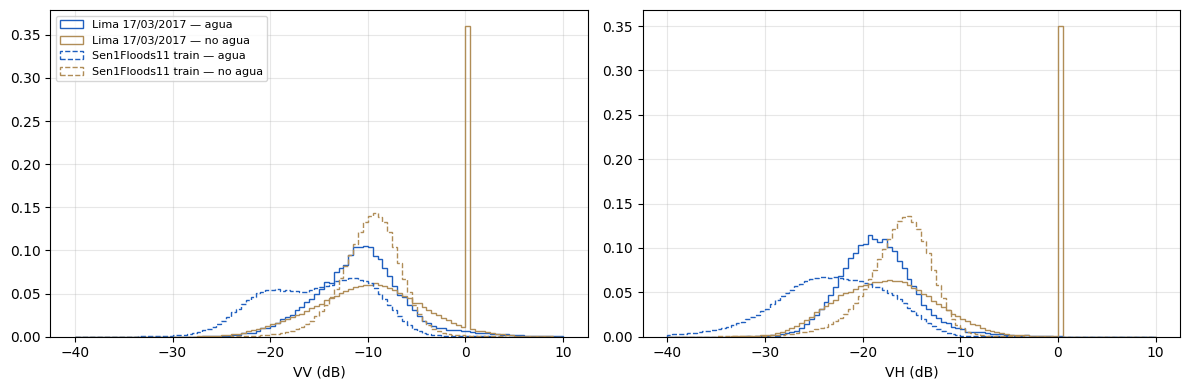

In [7]:
from src.descarga import descargar_mano
from src.lectura import leer_particion
from src.exploracion import muestrear_pixeles

descargar_mano()
pix_train = muestrear_pixeles(leer_particion('train')['id_chip'], n_por_clase=2000, semilla=SEMILLA)
pix_train['region'] = 'Sen1Floods11 train'

generador, partes = np.random.default_rng(SEMILLA), []
for id_chip in df_chips['id_chip']:
    s1 = leer(DIR_LIMA / 'chips' / 'S1Hand' / f'{id_chip}_S1Hand.tif')
    etiqueta = leer(DIR_LIMA / 'chips' / 'LabelHand' / f'{id_chip}_LabelHand.tif')[0]
    for clase in (0, 1):
        f, c = np.where(etiqueta == clase)
        if len(f):
            k = generador.choice(len(f), min(2000, len(f)), replace=False)
            partes.append(pd.DataFrame({'vv': s1[0, f[k], c[k]], 'vh': s1[1, f[k], c[k]], 'clase': clase}))
pix_lima = pd.concat(partes); pix_lima['region'] = 'Lima 17/03/2017'

pixeles = pd.concat([pix_train, pix_lima])
pixeles['clase'] = pixeles['clase'].map({0: 'no agua', 1: 'agua'})
tabla = pixeles.groupby(['region', 'clase'])[['vv', 'vh']].median().round(2)
tabla.to_csv(DIR_RESULTADOS / 'f8_distribucion_lima_vs_train.csv')
display(tabla)

figura, ejes = plt.subplots(1, 2, figsize=(12, 4))
for eje, banda in zip(ejes, ['vv', 'vh']):
    for (region, clase), grupo in pixeles.groupby(['region', 'clase']):
        estilo = '-' if region.startswith('Lima') else '--'
        color = '#1f5fbf' if clase == 'agua' else '#b08d57'
        eje.hist(grupo[banda], bins=100, range=(-40, 10), density=True, histtype='step', lw=1.8,
                 linestyle=estilo, color=color, label=f'{region} — {clase}')
    eje.set_xlabel(f'{banda.upper()} (dB)'); eje.grid(alpha=0.3)
ejes[0].legend(fontsize=8)
figura.tight_layout(); figura.savefig(DIR_FIGURAS / 'f8_distribucion_lima_vs_train.png', dpi=150, bbox_inches='tight')

## Para traer a la conversación
Salidas de las secciones 3 (escena y áreas) y 4 (resumen de chips), la figura de ejemplos (5) y la tabla + figura de distribuciones (6).
Después viene la **fase 8c**: evaluar el modelo final en Lima (y en Bolivia como respaldo) y medir la brecha frente a test.